# MethaneScope AI · Lesson 2.3
## Batch ingestion, data-quality checks, and duplicate prevention

**Objective:** Process multiple NASA EMIT methane plume granules safely, match GeoTIFFs with their *corresponding* GeoJSON metadata, validate structure, detect identical files and conflicting granule identifiers, and export a reproducible ingestion manifest.

**NASA product:** `EMITL2BCH4PLM.002` (NASA LP DAAC), DOI: [10.5067/EMIT/EMITL2BCH4PLM.002](https://doi.org/10.5067/EMIT/EMITL2BCH4PLM.002).

**Scientific safety:** EMIT plume raster values are methane **column enhancement** (`ppm m`). They are **not** emission rates (`kg/h`). Keep any NASA-supplied rate and uncertainty within the original GeoJSON metadata; we do not calculate emissions in this lesson.

**Important:** The default mode requires actual downloaded NASA files. If Lesson 2.1 did not finish, change `MODE = "real"` to `MODE = "demo"` in Cell 1. Demo mode generates clearly labelled *synthetic test files* in a separate directory and never represents them as NASA observations.

**What a passing result means:** Structural checks passed. This is **not** independent validation of the satellite retrieval, its science, or the authenticity of NASA files. Filename and hashes are not an Earthdata catalogue provenance verification.
**Correction (Lesson 2.3):** NASA EMIT V002 official plume metadata is commonly named `*.json` rather than `*.geojson`; the original inventory missed those companion files. This corrected notebook supports both extensions, preserving strict validation.


**Updated pairing fix:** EMIT metadata files can have `CH4PLMMETA` in the name even when raster files use `CH4PLM`. The pairing function now normalizes the product-prefix difference and uses the complete version, timestamp and plume ID; original filenames remain unchanged. Structural QC can still return `REVIEW` if metadata structure or raster geometry fails validation.

## 1 · Configure the notebook

Keep the notebook inside your `MethaneScope` folder (or `MethaneScope/notebooks`). Earlier NASA downloads should be in `data/raw/nasa_emit`. We intentionally **do not** download new data automatically.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.transform import from_origin
from rasterio.warp import transform_bounds
from shapely.geometry import shape, box

MODE = "real"  # Change to "demo" ONLY if real NASA files are not available
MAX_RASTERS = 100  # Safety cap for this training run
assert MODE in {"real", "demo"}

# Find MethaneScope root when Jupyter starts from project root or notebooks/
options = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in options if (p / "data").is_dir()), Path.cwd())
RAW = ROOT / "data" / "raw" / "nasa_emit"
DEMO = ROOT / "data" / "demo_emit_batch"
OUT = ROOT / "outputs" / "emit_batch"
OUT.mkdir(parents=True, exist_ok=True)
SOURCE = RAW if MODE == "real" else DEMO

print("Project root:", ROOT)
print("Mode:", MODE.upper())
print("Input directory:", SOURCE)
print("Output directory:", OUT)

Project root: C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\MethaneScope
Mode: REAL
Input directory: C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\MethaneScope\data\raw\nasa_emit
Output directory: C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\MethaneScope\outputs\emit_batch


## 2 · Optional: generate an **explicitly synthetic** batch for testing

If `MODE == "demo"`, this cell generates: three valid example plume granules, a byte-identical duplicate, an incomplete granule with no GeoJSON, and a corrupted TIFF. These are artificial QA test fixtures, *not* EMIT measurements. When `MODE == "real"`, this cell does nothing.

This helps us prove the pipeline flags each failure mode before processing valuable satellite products.

In [2]:
def make_demo_data(folder):
    folder.mkdir(parents=True, exist_ok=True)
    stamps = ["20260301T101010", "20260302T101010", "20260303T101010"]
    for index, stamp in enumerate(stamps, start=1):
        stem = f"EMIT_L2B_CH4PLM_002_{stamp}_{index:06d}"
        tif = folder / f"{stem}.tif"
        geo = folder / f"{stem}.geojson"
        yy, xx = np.mgrid[0:40, 0:45]
        values = (np.exp(-((xx-(20+index))**2/70 + (yy-19)**2/42)) * 140).astype('float32')
        transform = from_origin(28 + index * 0.1, -17, .0007, .0007)
        with rasterio.open(tif, 'w', driver='GTiff', height=40, width=45,
                           count=1, dtype='float32', crs='EPSG:4326',
                           transform=transform, nodata=-9999.) as src:
            src.write(values, 1)
            src.update_tags(data_origin='SYNTHETIC_QA_TEST', units='ppm m')
        west = 28 + index * 0.1
        feature = {"type":"FeatureCollection","features":[{
            "type":"Feature",
            "properties":{"dataset":"SYNTHETIC_QA_TEST", "plume_number":index},
            "geometry":{"type":"Polygon","coordinates":[[
                [west+.003,-17.003],[west+.027,-17.003],
                [west+.027,-17.024],[west+.003,-17.024],[west+.003,-17.003]
            ]]}
        }]}
        geo.write_text(json.dumps(feature, indent=2), encoding='utf-8')

    # Same exact bytes and same logical ID, but in another folder
    dup_dir = folder / 'duplicate_copy'
    dup_dir.mkdir(exist_ok=True)
    original = folder / f"EMIT_L2B_CH4PLM_002_{stamps[0]}_000001.tif"
    (dup_dir / original.name).write_bytes(original.read_bytes())

    # Valid raster without companion GeoJSON -> REVIEW
    missing = folder / 'EMIT_L2B_CH4PLM_002_20260304T101010_000004.tif'
    missing.write_bytes(original.read_bytes())  # same bytes -> would be exact duplicate!
    # Make it different while maintaining a valid raster: adjust its header tags
    with rasterio.open(missing, 'r+') as src:
        src.update_tags(data_origin='SYNTHETIC_QA_MISSING_GEOJSON')

    # Invalid raster bytes -> REJECTED
    (folder / 'EMIT_L2B_CH4PLM_002_20260305T101010_000005.tif').write_text(
        'This is intentionally not a TIFF. SYNTHETIC_QA_TEST', encoding='utf-8')

if MODE == "demo":
    make_demo_data(DEMO)
    print("Created synthetic fixtures in:", DEMO)
else:
    print("REAL mode: no synthetic files were created.")

REAL mode: no synthetic files were created.


## 3 · Inventory available rasters and metadata

**NASA documentation calls plume metadata GeoJSON but uses the `.json` file extension.** This revised exercise recognises both `.json` and `.geojson`. Match the full `(version, acquisition timestamp, plume ID)` after normalizing the NASA metadata asset identifier `CH4PLMMETA` to `CH4PLM`; do not rename source files or disable checks.


In [3]:
if not SOURCE.is_dir():
    raise FileNotFoundError(
        f"Missing {SOURCE}. Complete Lesson 2.1 NASA download, "
        "or change MODE to 'demo' in Cell 1 and rerun."
    )

rasters = sorted(p for p in SOURCE.rglob('*')
                 if p.is_file() and p.suffix.lower() in {'.tif', '.tiff'})
vectors = sorted(p for p in SOURCE.rglob('*')
                 if p.is_file() and p.suffix.lower() in {'.geojson', '.json'})

if not rasters:
    raise FileNotFoundError(
        f"No TIFF files found in {SOURCE}. Run Lesson 2.1 download or select MODE='demo'."
    )
if len(rasters) > MAX_RASTERS:
    print(f"Processing first {MAX_RASTERS} of {len(rasters)} TIFF files for this exercise.")
    rasters = rasters[:MAX_RASTERS]

print(f"Found {len(rasters)} GeoTIFF files and {len(vectors)} GeoJSON files")
for p in rasters[:10]:
    print(' TIFF:', p.relative_to(ROOT))
for p in vectors[:5]:
    print(' META:', p.relative_to(ROOT))

Found 1 GeoTIFF files and 1 GeoJSON files
 TIFF: data\raw\nasa_emit\EMIT_L2B_CH4PLM_002_20220810T064957_000485.tif
 META: data\raw\nasa_emit\EMIT_L2B_CH4PLMMETA_002_20220810T064957_000485.json


## 4 · Write reusable validation functions

We verify: product-specific filename; SHA-256 checksum; expected single raster band; CRS; usable finite pixels; and metadata pairing. An incomplete, ambiguous, or corrupted granule must not enter our accepted table.

**Status meanings**

- `ACCEPTED`: implemented **structural** checks passed; scientific validity is unverified.
- `REVIEW`: file is readable but metadata or geospatial checks require investigation.
- `REJECTED`: corrupted, empty, wrongly structured, or from the wrong product/version.
- `DUPLICATE`: exact same bytes were previously encountered in this batch.
- `CONFLICT`: same logical granule identifier but different raster bytes; needs manual reconciliation.

In [4]:
EMIT_V2 = re.compile(
    r'^EMIT_L2B_CH4PLM_(?P<version>\d{3})_(?P<timestamp>\d{8}T\d{6})_(?P<plume_id>[A-Za-z0-9]+)$',
    re.IGNORECASE
)

def sha256_file(path, chunk_bytes=1024*1024):
    digest = hashlib.sha256()
    with path.open('rb') as fh:
        for block in iter(lambda: fh.read(chunk_bytes), b''):
            digest.update(block)
    return digest.hexdigest()

def emit_plume_key(path):
    """Normalize documented EMIT metadata asset prefixes, preserving version/time/ID.

    e.g. EMIT_L2B_CH4PLMMETA_002_20220810T064957_000485.json
      -> EMIT_L2B_CH4PLM_002_20220810T064957_000485
    """
    stem = path.stem.casefold()
    prefix = "emit_l2b_ch4plmmeta_"
    if stem.startswith(prefix):
        return "emit_l2b_ch4plm_" + stem[len(prefix):]
    return stem


def pair_geojson(tif, candidates):
    """Pair a CH4PLM raster to its CH4PLM/CH4PLMMETA JSON by full identity.

    Prefer exactly one match beside the TIFF. Do not guess among ambiguous
    matches and never rename, delete or rewrite NASA's original source files.
    """
    key = emit_plume_key(tif)
    matches = [p for p in candidates if emit_plume_key(p) == key]
    local = [p for p in matches if p.parent == tif.parent]

    if len(local) == 1:
        return local[0], None
    if len(local) > 1:
        return None, 'Multiple local metadata files match this plume: manual review needed'
    if len(matches) == 1:
        return matches[0], None
    if len(matches) > 1:
        return None, 'Multiple metadata files match this plume across folders'
    return None, 'Missing matching GeoJSON metadata (CH4PLM/CH4PLMMETA)'

def inspect_geojson(path, raster_bounds, raster_crs):
    warnings = []
    if path is None:
        return ['Matching GeoJSON not found'], 0, []
    try:
        document = json.loads(path.read_text(encoding='utf-8'))
        # NASA's geospatial metadata uses JSON content, commonly with a .json suffix.
        # GeoJSON permits either a Feature or a FeatureCollection.
        if document.get('type') == 'FeatureCollection':
            feats = document.get('features', [])
        elif document.get('type') == 'Feature':
            feats = [document]
        else:
            return ['Metadata is neither GeoJSON Feature nor FeatureCollection'], 0, []
        if not feats:
            return ['GeoJSON contains no features'], 0, []
        polygons = []
        metadata_keys = set()
        for feature in feats:
            metadata_keys.update((feature.get('properties') or {}).keys())
            geom = feature.get('geometry')
            if not geom:
                warnings.append('Feature missing geometry')
                continue
            g = shape(geom)
            if g.is_empty or not g.is_valid:
                warnings.append('Invalid or empty geometry')
            elif g.geom_type in {'Polygon','MultiPolygon'}:
                polygons.append(g)
        if not polygons:
            warnings.append('No valid polygon plume outline')
        elif raster_crs is not None:
            try:
                bounds_wgs84 = transform_bounds(
                    raster_crs, 'EPSG:4326', *raster_bounds, densify_pts=11)
                footprint = box(*bounds_wgs84)
                if not any(g.intersects(footprint) for g in polygons):
                    warnings.append('Plume geometry does not overlap raster extent')
            except Exception as exc:
                warnings.append(f'Unable to compare raster and vector footprints: {exc}')
        return warnings, len(feats), sorted(metadata_keys)
    except Exception as exc:
        return [f'Invalid or unreadable GeoJSON: {exc}'], 0, []

def inspect_raster(path):
    result = dict(width=None, height=None, band_count=None, crs=None,
                  valid_pixels=None, valid_fraction=None,
                  minimum_enhancement_ppm_m=None, maximum_enhancement_ppm_m=None,
                  mean_enhancement_ppm_m=None)
    errors, warnings = [], []
    bounds, crs = None, None
    try:
        with rasterio.open(path) as src:
            result.update(width=int(src.width), height=int(src.height),
                          band_count=int(src.count), crs=str(src.crs) if src.crs else None)
            bounds, crs = src.bounds, src.crs
            if src.count != 1:
                errors.append(f'Expected 1 band, found {src.count}')
            if src.crs is None:
                errors.append('Missing coordinate reference system (CRS)')
            elif src.crs.to_epsg() != 4326:
                warnings.append('Unexpected raster CRS for NASA EMIT plume product; review metadata')
            if src.count > 0:
                pixels = np.ma.masked_invalid(src.read(1, masked=True).astype('float64'))
                valid = pixels.compressed()
                result['valid_pixels'] = int(valid.size)
                result['valid_fraction'] = float(valid.size/(src.width*src.height))
                if valid.size == 0:
                    errors.append('Raster contains no finite, unmasked measurements')
                else:
                    result['minimum_enhancement_ppm_m'] = float(valid.min())
                    result['maximum_enhancement_ppm_m'] = float(valid.max())
                    result['mean_enhancement_ppm_m'] = float(valid.mean())
                    if result['valid_fraction'] < .01:
                        warnings.append('Less than 1% of pixels are valid; review masks')
    except Exception as exc:
        errors.append(f'Cannot read GeoTIFF: {type(exc).__name__}: {exc}')
    return result, errors, warnings, bounds, crs

In [5]:
# Verify NASA metadata pairing before executing quality checks
print("NASA plume raster / metadata pairing preview:")
for tif in rasters[:10]:
    metadata, problem = pair_geojson(tif, vectors)
    print("Raster:  ", tif.name)
    print("Metadata:", metadata.name if metadata else "NOT MATCHED")
    if problem:
        print("Review:  ", problem)
    print()


NASA plume raster / metadata pairing preview:
Raster:   EMIT_L2B_CH4PLM_002_20220810T064957_000485.tif
Metadata: EMIT_L2B_CH4PLMMETA_002_20220810T064957_000485.json



## 5 · Run the batch and classify observations

`SHA-256` catches identical files even under different names. We also track a **logical granule ID** derived from the official-style filename to identify same-ID/different-content conflicts. Processing the same batch twice should not multiply the accepted records.

We do **not** silently merge different plumes, even when their timestamps match.

In [6]:
def scan_batch(raster_files, metadata_files):
    seen_hash = {}
    seen_identity = {}
    records = []
    for path in sorted(raster_files):
        record = {
            'path': str(path.relative_to(ROOT)),
            'filename': path.name,
            'mode': MODE,
            'data_origin': 'SYNTHETIC_QA_TEST' if MODE == 'demo' else 'NASA_CANDIDATE_UNVERIFIED',
            'product': 'EMITL2BCH4PLM.002',
            'granule_id': path.stem,
            'raster_sha256': None,
            'geojson_path': None,
            'geojson_sha256': None,
            'duplicate_of': None,
            'feature_count': None,
            'metadata_fields': None,
            'status': None,
            'issues': [],
        }
        match = EMIT_V2.match(path.stem)
        if match is None or match.group('version') != '002':
            record['issues'].append('Filename not recognised as EMIT CH4PLM Version 002')
            record['status'] = 'REJECTED'
            records.append(record)
            continue
        try:
            checksum = sha256_file(path)
            record['raster_sha256'] = checksum
            record['record_id'] = f"EMIT_CH4PLM_002_{checksum[:20]}"
        except Exception as exc:
            record['issues'].append(f'Could not checksum raster: {exc}')
            record['status'] = 'REJECTED'
            records.append(record)
            continue
        if checksum in seen_hash:
            record['status'] = 'DUPLICATE'
            record['duplicate_of'] = seen_hash[checksum]
            record['issues'].append('Exact byte-for-byte duplicate raster')
            records.append(record)
            continue
        if path.stem.casefold() in seen_identity:
            record['status'] = 'CONFLICT'
            record['duplicate_of'] = seen_identity[path.stem.casefold()]
            record['issues'].append('Same granule ID with different raster content')
            records.append(record)
            continue
        seen_hash[checksum] = record['path']
        seen_identity[path.stem.casefold()] = record['path']

        tif_info, errors, warnings, bounds, crs = inspect_raster(path)
        record.update(tif_info)
        vector, pairing_issue = pair_geojson(path, metadata_files)
        if pairing_issue:
            warnings.append(pairing_issue)
        if vector is not None:
            record['geojson_path'] = str(vector.relative_to(ROOT))
            try:
                record['geojson_sha256'] = sha256_file(vector)
            except Exception as exc:
                warnings.append(f'Could not checksum GeoJSON: {exc}')
            if bounds is not None:
                vector_warnings, nfeat, keys = inspect_geojson(vector, bounds, crs)
                warnings.extend(vector_warnings)
                record['feature_count'] = nfeat
                record['metadata_fields'] = ', '.join(keys)
        if errors:
            record['status'] = 'REJECTED'
        elif warnings:
            record['status'] = 'REVIEW'
        else:
            record['status'] = 'ACCEPTED'
        record['issues'] = errors + warnings
        records.append(record)
    return records

records = scan_batch(rasters, vectors)

print('Batch status summary:')
print(pd.Series(Counter(r['status'] for r in records)).to_string())
for r in records:
    print(f"{r['status']:10} {r['filename']} | {('; '.join(r['issues']))[:120] or 'structural checks passed'}")

Batch status summary:
ACCEPTED    1
ACCEPTED   EMIT_L2B_CH4PLM_002_20220810T064957_000485.tif | structural checks passed


## 6 · Idempotency test: running the same batch twice

We recompute the manifest from the same inputs and compare it with the first pass. This validates deterministic *classification* in this notebook, rather than guaranteeing anything about a future database or changed upstream files.

In [7]:
again = scan_batch(rasters, vectors)
assert records == again, 'Unexpected difference between two identical runs'
print('PASS: same inputs -> same classified records')
print('Unique accepted granule IDs:', len({r['granule_id'] for r in records if r['status']=='ACCEPTED'}))
print('Accepted records:', sum(r['status']=='ACCEPTED' for r in records))

PASS: same inputs -> same classified records
Unique accepted granule IDs: 1
Accepted records: 1


## 7 · Export batch manifest and issues

The accepted file contains records eligible for **subsequent engineering ingestion**, not a claim that the methane values have been scientifically validated. The full manifest retains review, rejection, duplicate and conflict outcomes. A JSON issues report preserves explanations.

Outputs are regenerated, rather than appended, to avoid multiplying records when rerunning a notebook.

In [8]:
manifest_rows = []
for r in records:
    row = r.copy()
    row['issues'] = ' | '.join(r.get('issues', []))
    manifest_rows.append(row)

manifest = pd.DataFrame(manifest_rows)
accepted = manifest.loc[manifest['status'] == 'ACCEPTED'].copy()

manifest_path = OUT / 'emit_batch_manifest.csv'
accepted_path = OUT / 'emit_accepted_for_ingestion.csv'
issues_path = OUT / 'emit_batch_issues.json'
summary_path = OUT / 'emit_batch_summary.json'

manifest.to_csv(manifest_path, index=False)
accepted.to_csv(accepted_path, index=False)
issues = [{k:r.get(k) for k in ('path','granule_id','status','issues','duplicate_of')}
          for r in records if r['status'] != 'ACCEPTED']
issues_path.write_text(json.dumps(issues, indent=2), encoding='utf-8')
summary = {
    'mode': MODE,
    'data_origin': 'synthetic test fixtures' if MODE == 'demo' else 'NASA candidate files (not catalog-authenticated)',
    'total_rasters_processed': len(records),
    'counts_by_status': dict(Counter(r['status'] for r in records)),
    'scientific_validation': 'NOT_ESTABLISHED',
    'note': 'All raw source data preserved; values are enhancement, not emission rate',
}
summary_path.write_text(json.dumps(summary, indent=2), encoding='utf-8')

print('Saved outputs:')
for path in [manifest_path, accepted_path, issues_path, summary_path]:
    print(' ', path.relative_to(ROOT), f'({path.stat().st_size:,} bytes)')
print('\nAccepted preview:')
print(accepted[['granule_id','valid_pixels','maximum_enhancement_ppm_m']].to_string(index=False)
      if not accepted.empty else 'No accepted observations; inspect issues report')

Saved outputs:
  outputs\emit_batch\emit_batch_manifest.csv (1,158 bytes)
  outputs\emit_batch\emit_accepted_for_ingestion.csv (1,158 bytes)
  outputs\emit_batch\emit_batch_issues.json (2 bytes)
  outputs\emit_batch\emit_batch_summary.json (309 bytes)

Accepted preview:
                                granule_id  valid_pixels  maximum_enhancement_ppm_m
EMIT_L2B_CH4PLM_002_20220810T064957_000485          1967                 3037.61377


## 8 · Plot the batch quality distribution

The chart distinguishes healthy ingestions from records requiring action. In demo mode you should see accepted, duplicate, review, and rejected categories. The specific order and results in **real mode** depend on the files you downloaded.

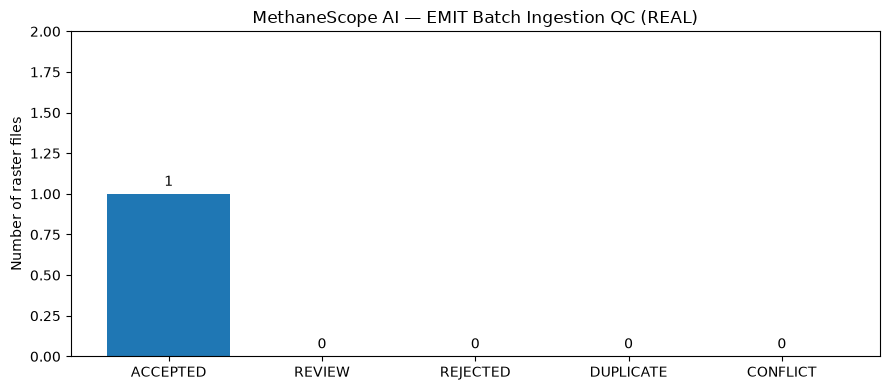

Saved: outputs\emit_batch\emit_batch_quality_distribution.png


In [9]:
order = ['ACCEPTED','REVIEW','REJECTED','DUPLICATE','CONFLICT']
counts = [sum(r['status']==label for r in records) for label in order]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(order, counts)
ax.set_title(f'MethaneScope AI — EMIT Batch Ingestion QC ({MODE.upper()})')
ax.set_ylabel('Number of raster files')
ax.set_ylim(0, max(counts)+1 if counts else 1)
for i, count in enumerate(counts):
    ax.text(i, count+0.05, str(count), ha='center', fontsize=10)
plt.tight_layout()
chart_path = OUT / 'emit_batch_quality_distribution.png'
plt.savefig(chart_path, dpi=150)
plt.show()
print('Saved:', chart_path.relative_to(ROOT))

## 9 · Interpretation and checkpoint

**Questions to answer in your project notes:**

1. What is the difference between an exact duplicate (`SHA-256`) and a same-granule conflict?
2. Why shouldn't a GeoJSON be matched to a GeoTIFF solely by observing that their timestamps are equal?
3. What does `ACCEPTED` demonstrate? What does it **not** demonstrate?
4. Why should we preserve the original input files and all rejected-file records?
5. How would you prevent duplicate writes if the same batch were sent to PostgreSQL twice?

**Show me these outputs:** (1) `Batch status summary`, (2) the bar chart, and (3) the final `Saved outputs` printout.

**If no NASA TIFFs are present:** Complete the real NASA download in Lesson 2.1, or set `MODE = "demo"` and rerun. Keep demo output separate and clearly labelled.

**Next lesson — 2.4:** We will define actual PostGIS tables, foreign keys, spatial indexes and database uniqueness constraints, then load only eligible observation records in a transaction. We will keep plume detections separate from confirmed emission-source identifications.

**Authoritative science reference:** [EMIT L2B greenhouse-gas V2 User Guide](https://lpdaac.usgs.gov/documents/2250/EMIT_L2B_GHG_User_Guide_V2.pdf).